# Activity 4
John Rendell B. Tapire
CPE4A

Input:`bills.png`.
The reference builds HSV masks for six bill colors, cleans the masks with morphology,
finds contours, and adds denomination values. Here, a background mask first isolates
each separate banknote. HSV evidence then assigns at most one denomination per note,
avoiding duplicate boxes caused by the many colors printed on a single bill.
This is a color classification exercise, not currency authentication.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Support a kernel started in either this activity folder or the project root.
activity_dir = Path.cwd()
if not (activity_dir / 'images').is_dir():
    activity_dir = activity_dir / 'Activity_04'
image_dir = activity_dir / 'images'
if not image_dir.is_dir():
    raise FileNotFoundError('Open the project root or this activity folder in VS Code.')

def show_stages(stages, columns=3):
    rows = (len(stages) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 3.6 * rows), squeeze=False)
    for axis, (title, picture) in zip(axes.flat, stages):
        axis.imshow(picture, cmap='gray' if picture.ndim == 2 else None)
        axis.set_title(title)
    for axis in axes.flat:
        axis.axis('off')
    plt.tight_layout()
    plt.show()

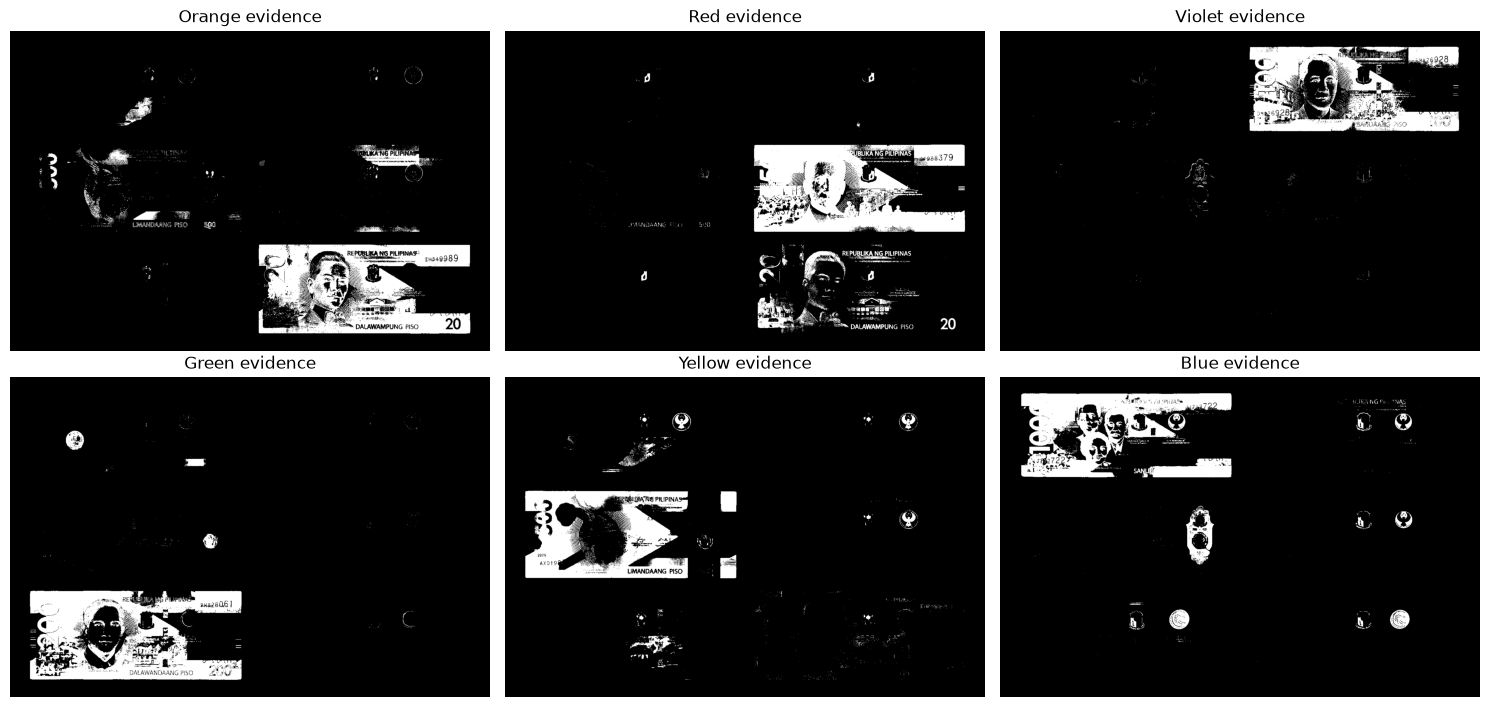

In [2]:
# 1. Read without stretching the image; hue measurements use OpenCV's 0..179 scale.
image = cv2.imread(str(image_dir / 'bills.png'))
if image is None:
    raise FileNotFoundError(image_dir / 'bills.png')
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Color intervals calibrated to the supplied image, not the reference student's image.
# Red wraps around hue 0, so it requires two ranges.
bill_colors = {
    'Orange': {'ranges': [((7, 60, 60), (17, 255, 255))], 'value': 20},
    'Red': {'ranges': [((0, 60, 60), (6, 255, 255)), ((170, 60, 60), (179, 255, 255))], 'value': 50},
    'Violet': {'ranges': [((125, 35, 50), (169, 255, 255))], 'value': 100},
    'Green': {'ranges': [((32, 35, 40), (85, 255, 255))], 'value': 200},
    'Yellow': {'ranges': [((18, 60, 60), (31, 255, 255))], 'value': 500},
    'Blue': {'ranges': [((86, 35, 40), (124, 255, 255))], 'value': 1000},
}

def build_mask(hsv_image, ranges):
    mask = np.zeros(hsv_image.shape[:2], dtype=np.uint8)
    for lower, upper in ranges:
        mask |= cv2.inRange(hsv_image, np.array(lower), np.array(upper))
    return mask

color_masks = {name: build_mask(hsv, info['ranges']) for name, info in bill_colors.items()}
show_stages([(name + ' evidence', mask) for name, mask in color_masks.items()])

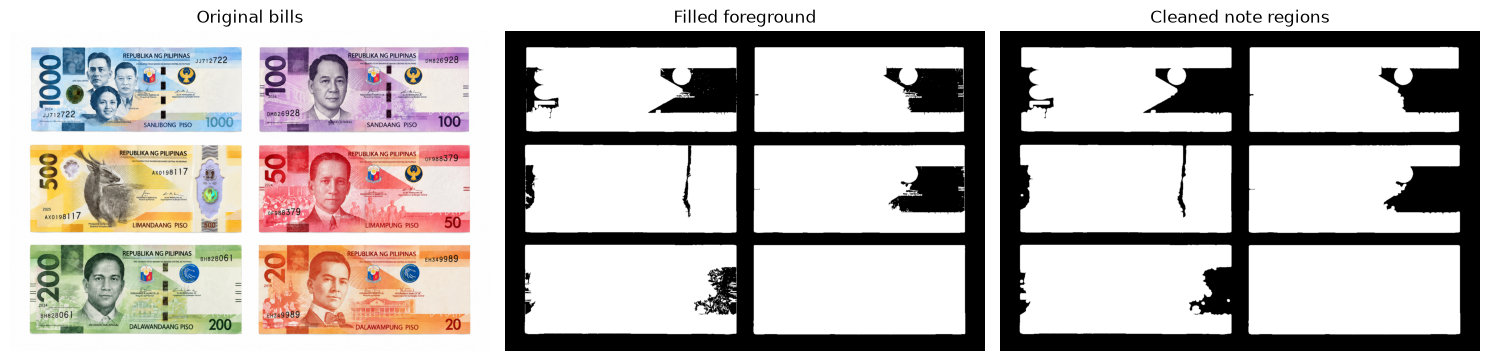

In [3]:
# 2. Segment complete notes before assigning a color to each one.
foreground = (~np.all(image_rgb > 220, axis=2)).astype(np.uint8) * 255
contours, _ = cv2.findContours(foreground, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
filled = np.zeros_like(foreground)
cv2.drawContours(filled, contours, -1, 255, thickness=cv2.FILLED)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
cleaned = cv2.morphologyEx(filled, cv2.MORPH_OPEN, kernel)
contours, _ = cv2.findContours(cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

note_boxes = []
for contour in contours:
    x, y, width, height = cv2.boundingRect(contour)
    if cv2.contourArea(contour) > foreground.size * 0.015 and 1.6 < width / height < 3.5:
        note_boxes.append((x, y, width, height))
note_boxes.sort(key=lambda box: (box[1], box[0]))
show_stages([('Original bills', image_rgb), ('Filled foreground', filled),
             ('Cleaned note regions', cleaned)])

In [4]:
# 3. Score color evidence inside each note, trimming the edge and bright paper.
# Every detected note contributes at most one value; ambiguous notes stay Unknown.
detections = []
for x, y, width, height in note_boxes:
    margin_x, margin_y = int(width * 0.04), int(height * 0.06)
    left, right = x + margin_x, x + width - margin_x
    top, bottom = y + margin_y, y + height - margin_y
    scores = {name: np.count_nonzero(mask[top:bottom, left:right])
              for name, mask in color_masks.items()}
    ranked = sorted(scores, key=scores.get, reverse=True)
    winner, runner_up = ranked[:2]
    support = scores[winner] / ((right - left) * (bottom - top))
    separation = scores[winner] / max(scores[runner_up], 1)
    accepted = support >= 0.08 and separation >= 1.15
    label = winner if accepted else 'Unknown'
    value = bill_colors[winner]['value'] if accepted else None
    detections.append({'color': label, 'value': value, 'box': (x, y, width, height)})
    print(f'Box {(x, y, width, height)}: {label}, support={support:.1%}, '
          f'best/second={separation:.2f}; color pixels={scores}')

Box (68, 51, 673, 272): Blue, support=50.2%, best/second=20.31; color pixels={'Orange': np.int64(2910), 'Red': np.int64(333), 'Violet': np.int64(134), 'Green': np.int64(3685), 'Yellow': np.int64(3648), 'Blue': np.int64(74844)}
Box (798, 51, 671, 273): Violet, support=52.0%, best/second=31.38; color pixels={'Orange': np.int64(269), 'Red': np.int64(435), 'Violet': np.int64(77594), 'Green': np.int64(43), 'Yellow': np.int64(1375), 'Blue': np.int64(2473)}
Box (64, 364, 677, 282): Yellow, support=43.2%, best/second=6.77; color pixels={'Orange': np.int64(9947), 'Red': np.int64(573), 'Violet': np.int64(755), 'Green': np.int64(1442), 'Yellow': np.int64(67305), 'Blue': np.int64(7478)}
Box (796, 365, 676, 281): Red, support=64.3%, best/second=14.28; color pixels={'Orange': np.int64(6968), 'Red': np.int64(99532), 'Violet': np.int64(207), 'Green': np.int64(29), 'Yellow': np.int64(1375), 'Blue': np.int64(1782)}
Box (63, 684, 678, 287): Green, support=58.0%, best/second=24.82; color pixels={'Orange':

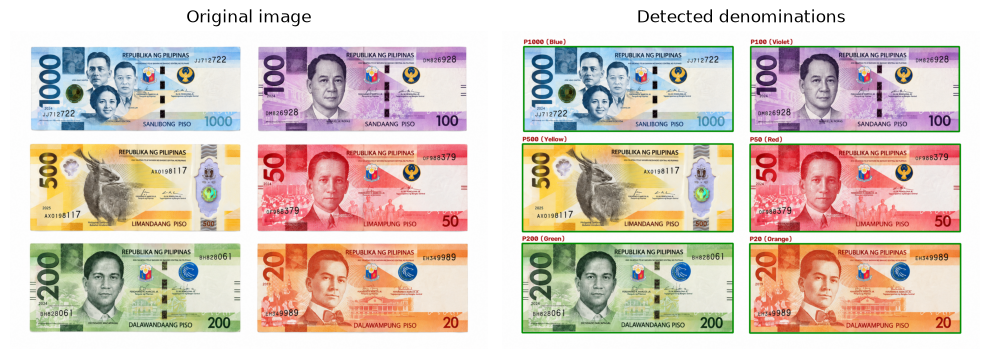

Detected banknotes: 6
Recognized denominations: [1000, 100, 500, 50, 200, 20]
Total recognized value: P1870
Unclassified notes: 0


In [5]:
# 4. Annotate detected denominations and sum only classified notes.
result = image_rgb.copy()
for detection in detections:
    x, y, width, height = detection['box']
    value = detection['value']
    text = f'P{value} ({detection["color"]})' if value is not None else 'Unknown bill'
    cv2.rectangle(result, (x, y), (x + width, y + height), (0, 140, 0), 3)
    cv2.putText(result, text, (x, max(24, y - 8)), cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (160, 0, 0), 2)
known_values = [item['value'] for item in detections if item['value'] is not None]
total_value = sum(known_values)
unknown_count = len(detections) - len(known_values)
show_stages([('Original image', image_rgb), ('Detected denominations', result)], columns=2)
print(f'Detected banknotes: {len(detections)}')
print(f'Recognized denominations: {known_values}')
print(f'Total recognized value: P{total_value}')
print(f'Unclassified notes: {unknown_count}')
if unknown_count:
    print('The recognized subtotal excludes unclassified notes.')

Each denomination maps to a measured hue range; the final result is not hardcoded.
Lighting, overlapping notes, and different banknote series can change these colors.
The masks and printed scores make it possible to inspect a classification and adjust
thresholds. Coins are handled separately in Activity 3.